In [362]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [363]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# EDA 

In [364]:
display(df.duplicated().sum())
display(df.isnull().sum())
display(df.info())

np.int64(0)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

None

tidak terdapat data duplikat dan missing value, namun terdapat keslahan tipedata pada totalcharges yang seharusnya bertipa int

In [365]:
# simpan nilai asli
df['TotalCharges_original'] = df['TotalCharges'].copy()

# konversi
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# cari yang jadi NaN
mask_nan = df['TotalCharges'].isnull()

print("Jumlah yang jadi NaN:", mask_nan.sum())
print()
print("Baris yang jadi NaN, dengan nilai asli:")
print(df.loc[mask_nan, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges_original', 'TotalCharges', 'Churn']])
print()
print("Tipe nilai asli:")
print(df.loc[mask_nan, 'TotalCharges_original'].apply(type).value_counts())
print()
print("Repr nilai asli (biar kelihatan spasi/string kosong):")
for v in df.loc[mask_nan, 'TotalCharges_original'].unique():
    print(repr(v))

Jumlah yang jadi NaN: 11

Baris yang jadi NaN, dengan nilai asli:
      customerID  tenure  MonthlyCharges TotalCharges_original  TotalCharges  \
488   4472-LVYGI       0           52.55                                 NaN   
753   3115-CZMZD       0           20.25                                 NaN   
936   5709-LVOEQ       0           80.85                                 NaN   
1082  4367-NUYAO       0           25.75                                 NaN   
1340  1371-DWPAZ       0           56.05                                 NaN   
3331  7644-OMVMY       0           19.85                                 NaN   
3826  3213-VVOLG       0           25.35                                 NaN   
4380  2520-SGTTA       0           20.00                                 NaN   
5218  2923-ARZLG       0           19.70                                 NaN   
6670  4075-WKNIU       0           73.35                                 NaN   
6754  2775-SEFEE       0           61.90              

In [366]:
df = df.drop(columns=['customerID','TotalCharges_original'])

terdapat missing value pada totalcharges, untuk penanganan missing value akan dianalisis lebih lanjut pada tahap selanjutnya

## Numerical analysis

count    7043.000000
mean        0.162147
std         0.368612
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: SeniorCitizen, dtype: float64


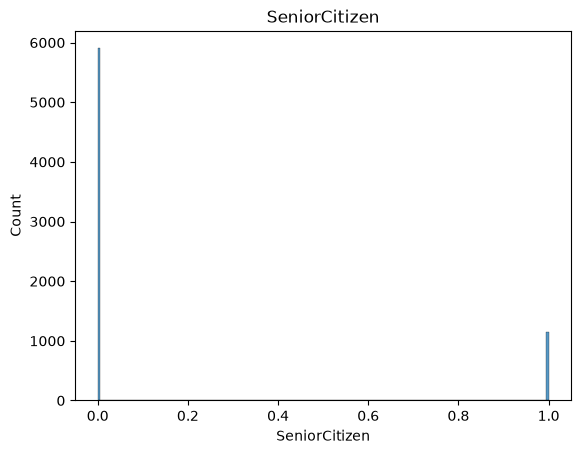

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


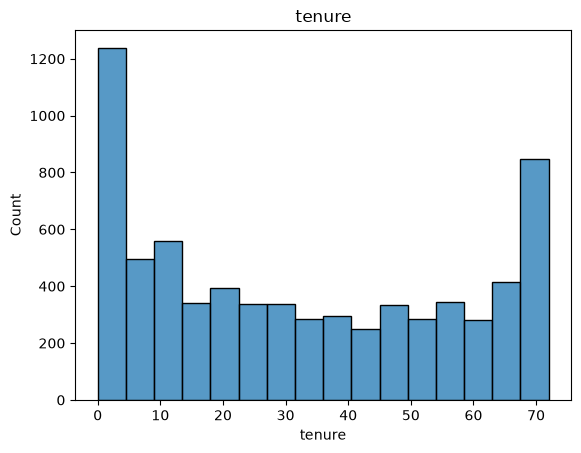

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64


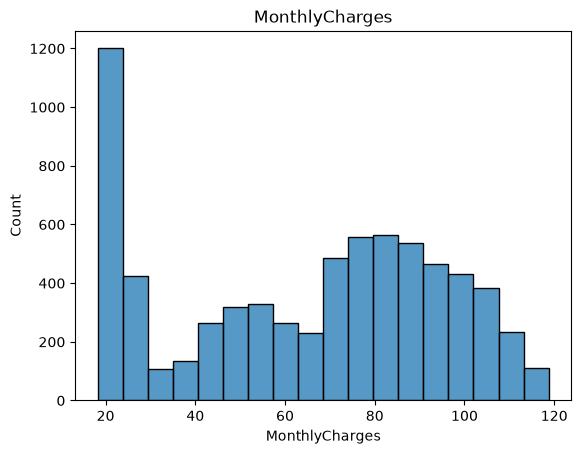

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


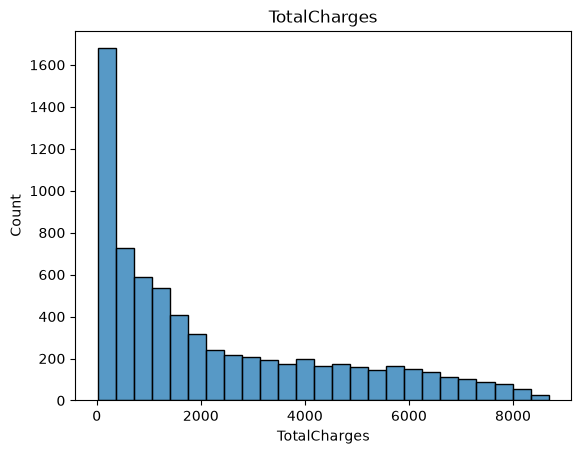

In [367]:
num_cols = df.select_dtypes(include='number')
for i in num_cols :
    print(df[i].describe())
    print("===========================================")
    sns.histplot(data=df, x=i)
    plt.title(i)
    plt.show()

berdasarkan analisi diatas, dapat kita lihat bahwa kebayakan pelanggan pada perusahaan Telco ini bukan merupakan senior citizen. terdapat right skewed pada tenure, monthly charges, dan totalcharges

### Totalcharges

In [368]:
df[df['tenure'] * df['MonthlyCharges'] != df['TotalCharges']].count()

gender              6429
SeniorCitizen       6429
Partner             6429
Dependents          6429
tenure              6429
PhoneService        6429
MultipleLines       6429
InternetService     6429
OnlineSecurity      6429
OnlineBackup        6429
DeviceProtection    6429
TechSupport         6429
StreamingTV         6429
StreamingMovies     6429
Contract            6429
PaperlessBilling    6429
PaymentMethod       6429
MonthlyCharges      6429
TotalCharges        6418
Churn               6429
dtype: int64

dalam analisis diatas dapat kita lihat hampir semua row memiliki totalcharge yang sesuai yaitu tenure x monthly charges. meski terdapat beberpaa baris yang terlewat, peneliti memutuskan untuk mengisi totalcharges berdasarkan tenure * monthlycharges

In [369]:
df.groupby("tenure")['TotalCharges'].agg(['mean','median','count'])

,mean,median,count
tenure,,,
0,NaN,NaN,0
1,50.485808,49.750,613
2,114.332353,118.275,238
3,174.690000,192.775,200
4,230.530682,236.425,176
...,...,...,...
68,5006.300000,5574.650,100
69,4876.041579,5553.250,95
70,5349.057143,5717.850,119


In [370]:
df[df['tenure'] ==0]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [371]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'])

berdasarkan analisis diatas, dapat kita lihat bahwa totalcharges yang null itu dikarenakan pelanggan baru saja memulai layanannya sehingga TotalChargesnya masih belum di update. oleh karena itu peneliti memutuskan untuk mengisi missing value dengan monthlychargesnya

## Categorical Analysis

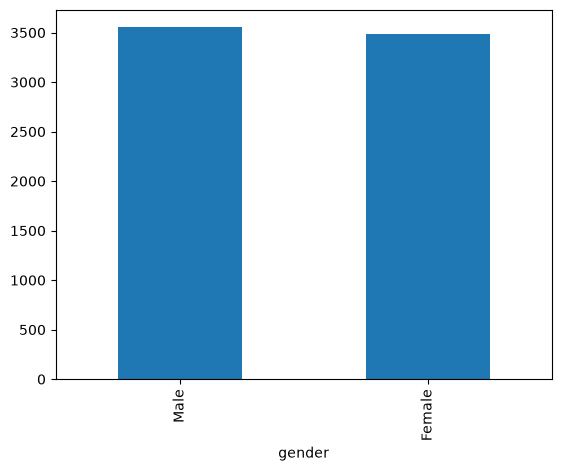

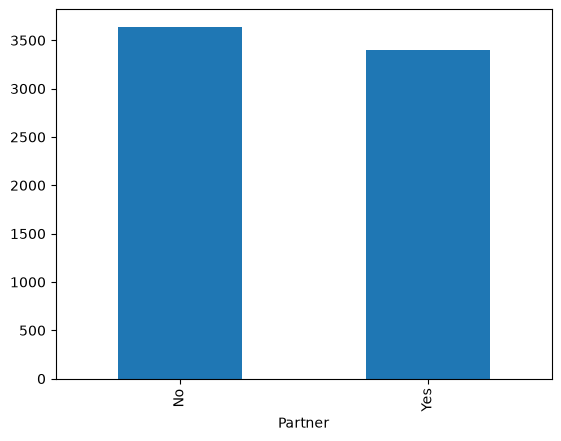

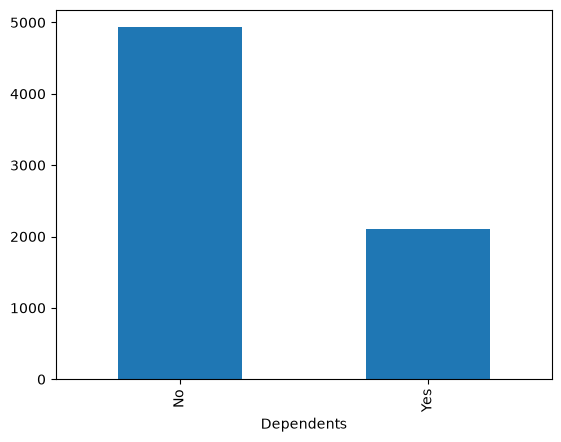

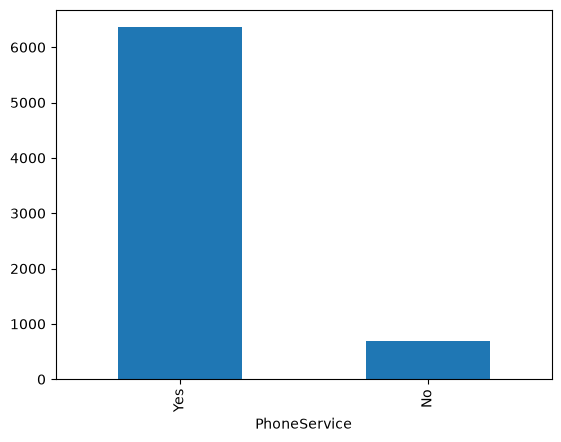

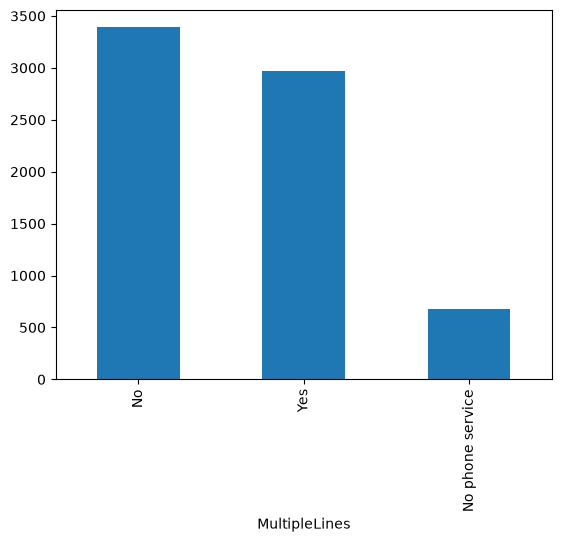

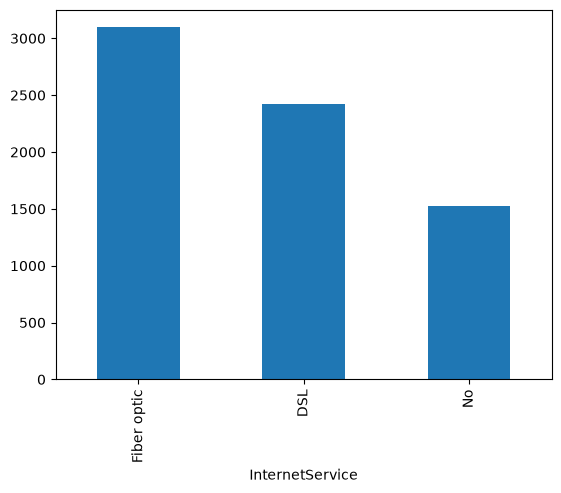

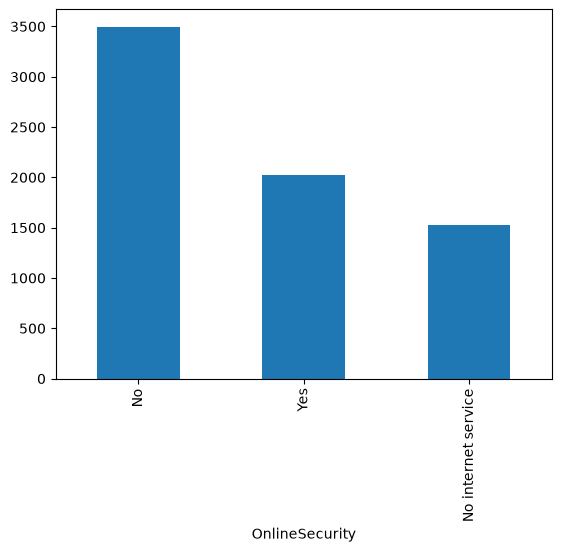

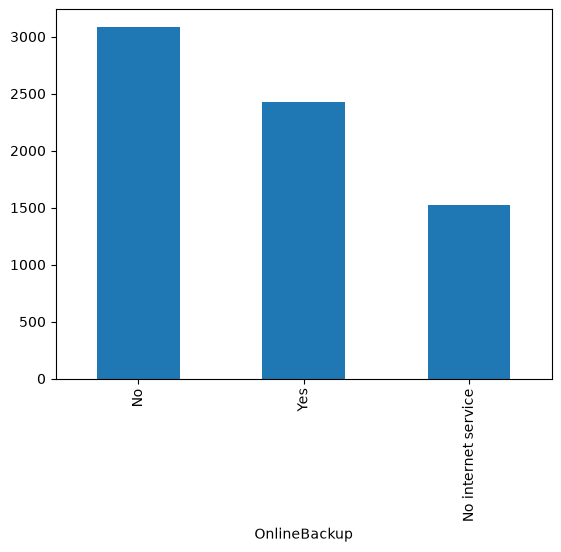

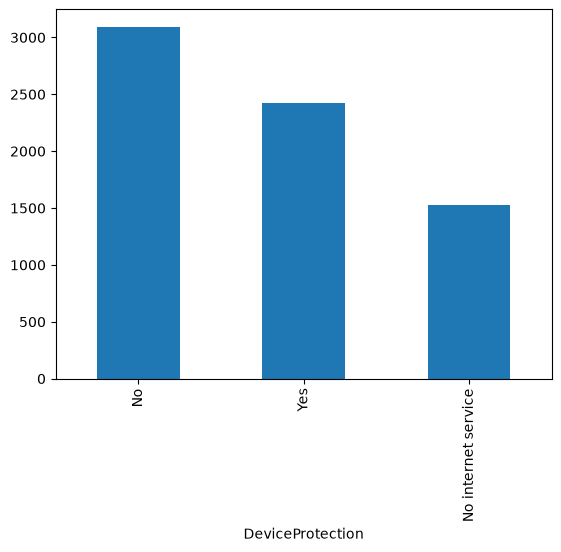

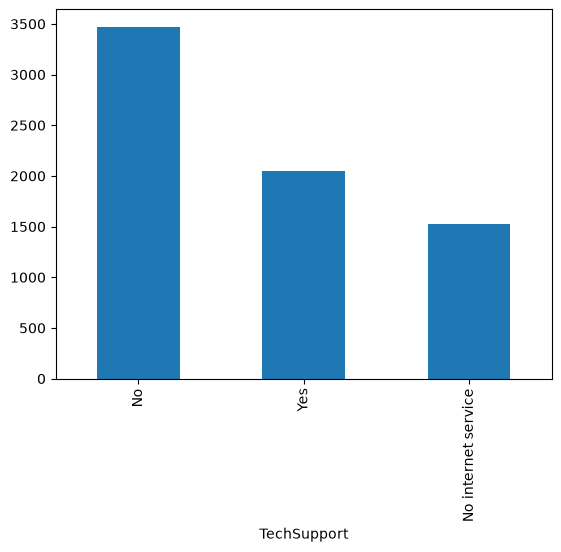

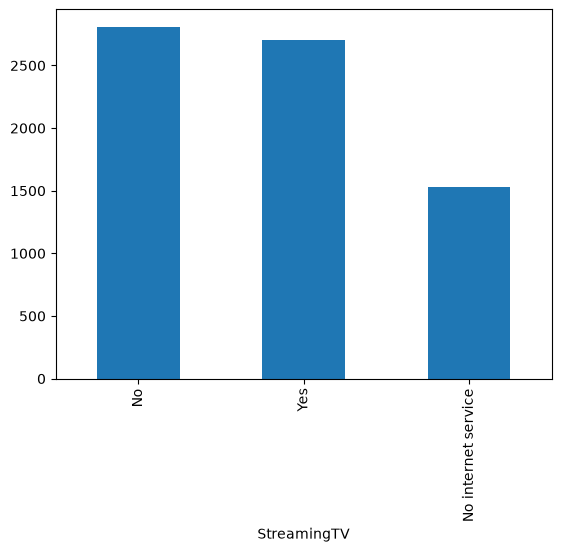

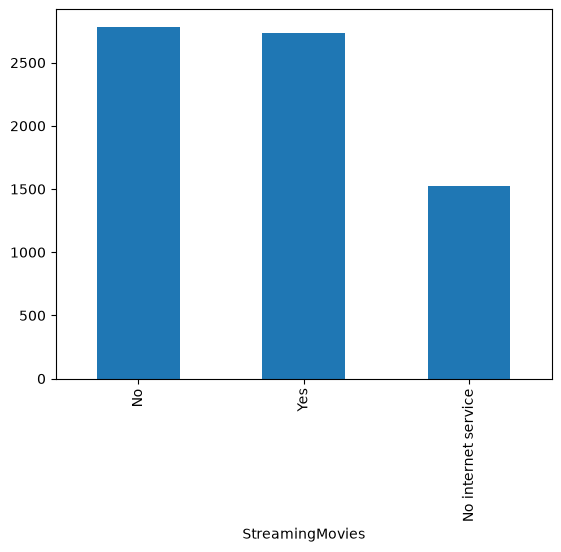

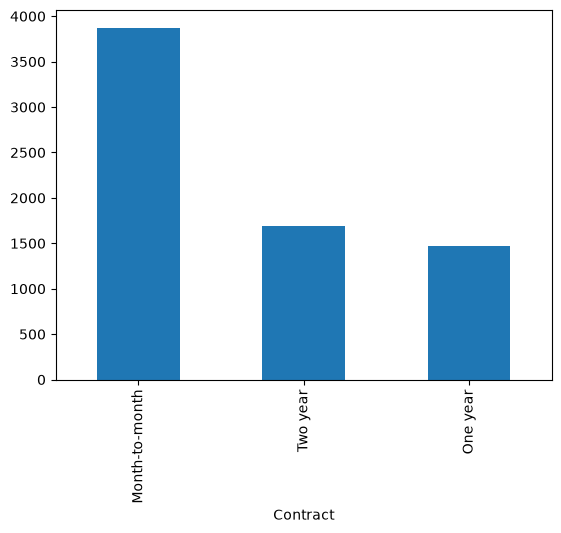

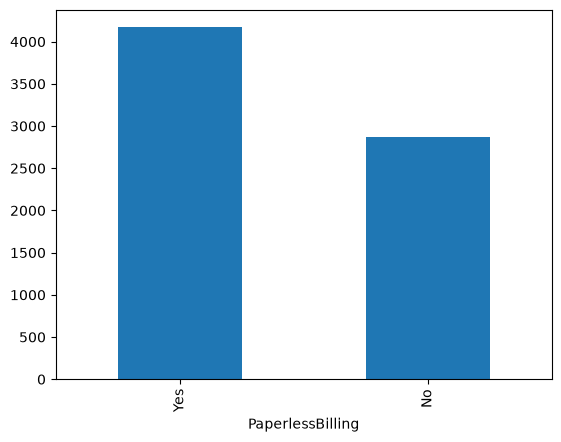

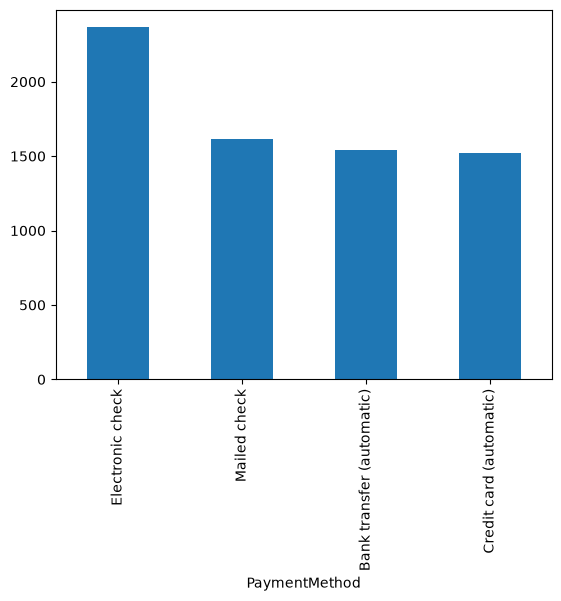

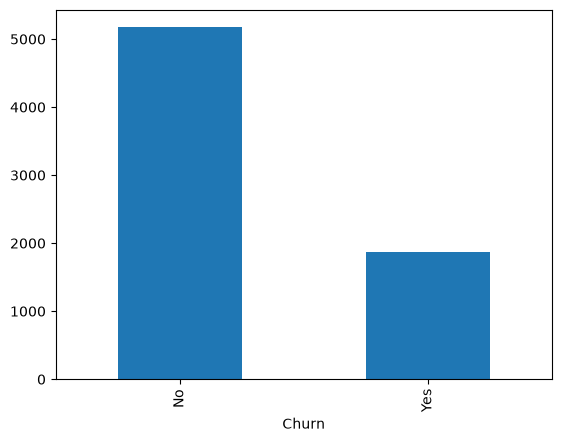

In [372]:
obj_cols = df.select_dtypes(include=['object','str','category'])
for i in obj_cols :
    ct = df[i].value_counts()
    ct.plot(kind='bar')
    plt.show()
    print("====================================")

berdasarkann analisis diatas, terdapat class imbalance pada churn dimana kelas minoritas berada pada pelanggan yang churn. selain itu, beberapa fitur memiliki distribusi yang tidak setara seperti phoneservice yang didominasi oleh yes dan dependent yang didominasi oleh no. 

### Consistency Feature

In [373]:
consistent_check = ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingMovies','StreamingTV']

for i in consistent_check :
    print(i)
    print(len(df[(df['InternetService'] == "No") & (df[i] != "No internet service")]))

OnlineSecurity
0
OnlineBackup
0
DeviceProtection
0
TechSupport
0
StreamingMovies
0
StreamingTV
0


In [374]:
print(len(df[(df['PhoneService'] == 'No') & (df['MultipleLines'] !="No phone service")]))

0


## Correlation

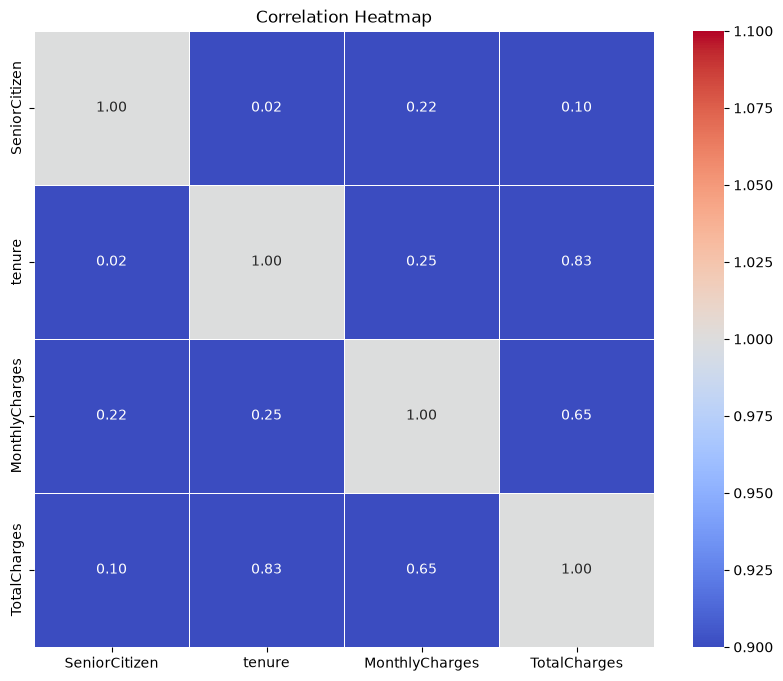

In [375]:
numeric_df = df.select_dtypes(include='number')
corr_matrix = numeric_df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths = 0.5,vmin=1,vmax=1)

plt.title("Correlation Heatmap")
plt.show()

Berdasarkan korelasi heatmap. dapat dilihat bahwa terdapat beberapa variabel yang memiliki korelasi kuat. seperti tenure dengan totalcharges,, kemudian monthlycharges dengan totalservices, dan totalcharges dengan totalservice. hal ini diasumsikan bahwa semakin banyak totalservice, maka monthlycahrgesnya akan semakin mahal dan semakin lama seseorang berlangganan di perusahaan ini (tenure), maka semakin banyak juga totalchargesnya. Analisis tersebut akan dilihat pada Dive Deeper EDA

# Dive Deeper Numerical Analysis

In [376]:
from scipy.stats import chi2_contingency

def cek_signifikansi_fitur(df, kolom_fitur, kolom_target='Churn'):
  # 1. Membuat tabel kontingensi (tabel silang) antara fitur dan target
  contingency_table = pd.crosstab(df[kolom_fitur], df[kolom_target])

  # 2. Menjalankan uji Chi-Square
  chi2, p_val, dof, expected = chi2_contingency(contingency_table)

  # 3. Menampilkan hasil dengan rapi
  print(f'=== UJI STATISTIK: {kolom_fitur} vs {kolom_target} ===')
  print(f'Nilai p-value: {p_val:.5f}')

  # 4. Kesimpulan otomatis berdasarkan alpha 0.05
  if p_val < 0.05:
    print(
        '👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan'
        ' karena kebetulan).'
    )
  else:
    print(
        '👉 Status: **TIDAK SIGNIFIKAN** (Perbedaan proporsinya bisa jadi cuma'
        ' karena kebetulan data).'
    )
  print('-' * 50)
  print('\n')

In [377]:
display(df.groupby("Churn")['SeniorCitizen'].agg(['mean','median','count']))
cek_signifikansi_fitur(df, 'SeniorCitizen')

,mean,median,count
Churn,,,
No,0.128721,0.0,5174
Yes,0.254682,0.0,1869


=== UJI STATISTIK: SeniorCitizen vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




## Senior Citizen

hampir semua semuanya yang churn merupakan Senior Citizen. mengapa kelompok Senior Citizen lebih banyak melakukan churn?

<Axes: xlabel='SeniorCitizen'>

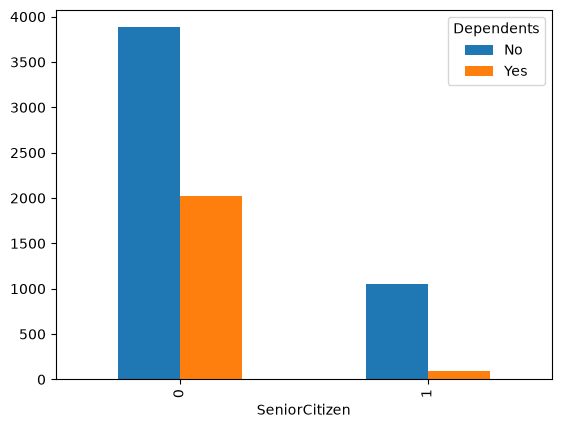

In [378]:
ct = pd.crosstab(df['SeniorCitizen'],df['Dependents'])
ct.plot(kind='bar')

menguji hipotesis terhadap seniorcitizen yang memiliki dependent cenderung churn karena memiliki biaya tanggungan lain yang harus dibayar. namun hal ini terbukti gagal yang terlihat pada barplot bahwa hanya sedikit senior citizen yang memiliki tanggungan lain. Selanjutnya adalah apakah seniorzitizen memiliki monthlycharges yang lebih besar daripada yang tidak sehingga menyebabkan churn

In [379]:
df.groupby("SeniorCitizen")['MonthlyCharges'].agg(['mean','median','count'])


,mean,median,count
SeniorCitizen,,,
0,61.847441,65.80,5901
1,79.820359,84.85,1142


In [380]:
service_columns = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
]

# 1. Menghitung layanan "Yes" dari list kolom
# 2. Menambahkan (True/False yang otomatis jadi 1/0) jika InternetService bukan "No"
df['TotalServices'] = (df[service_columns] == 'Yes').sum(
    axis=1
) + (df['InternetService'] != 'No')

In [381]:
df.groupby("SeniorCitizen")['TotalServices'].agg(['mean','median','count'])

,mean,median,count
SeniorCitizen,,,
0,4.026097,4.0,5901
1,4.767075,5.0,1142


berdasarkan hasil analisis diatas, dapat dilihat bahwa senior citizen memiliki monthly charges yang lebih besar daripada yang tidak, namun setelah pengujian hipotesis bahwa senior citizen cenderung memiliki totalservice yang lebih banyak. ternyata hipotesis tersebut gagal karena nilainya cenderung hampir mirip

<Axes: xlabel='SeniorCitizen'>

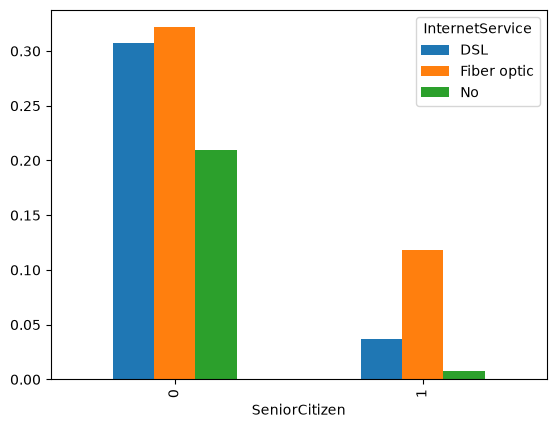

In [382]:
ct = pd.crosstab(df['SeniorCitizen'],df['InternetService'],normalize=True)
ct.plot(kind='bar')

<Axes: xlabel='SeniorCitizen'>

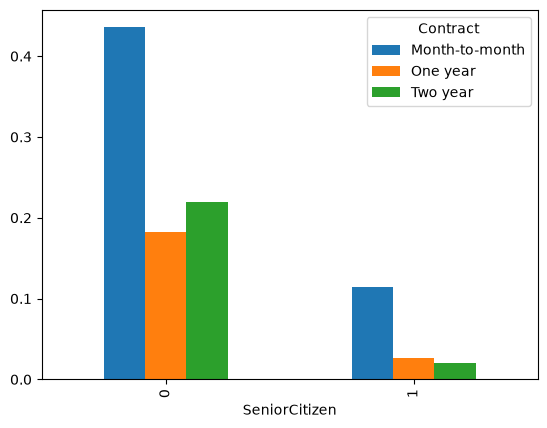

In [383]:
ct = pd.crosstab(df['SeniorCitizen'],df['Contract'], normalize=True)
ct.plot(kind='bar')

setelah dilakukan analisis lebih dalam, tidak ditemukan alasan yang signifikan yang menunjukkan mengapa seniorcitizen memiliki monthlycharges yang lebih besar. berdasarkan hipotesis jumlah service dan juga kontrak. tidak ditemukan pola signifikan pada kelompok senior citizen

In [384]:
df.groupby('SeniorCitizen')['tenure'].agg(['mean','median','count'])

,mean,median,count
SeniorCitizen,,,
0,32.192171,28.0,5901
1,33.295972,31.0,1142


Peneliti tidak menemukan pola atuapun alasan yang jelas terkait kelompok ini sehingga peneliti memutuskan untuk berhenti menelusuri lebih dalam. Oleh karena itu, dibutuhkan penanganan yang lebih lanjut pada kelompok ini

## Tenure

In [385]:
df.groupby("Churn")['tenure'].agg(['mean','median','count'])

,mean,median,count
Churn,,,
No,37.569965,38.0,5174
Yes,17.979133,10.0,1869


In [386]:
display(pd.crosstab(df['Contract'],df['Churn']))
display(df.groupby('Contract')['tenure'].agg(['mean','median','count']))

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


,mean,median,count
Contract,,,
Month-to-month,18.036645,12.0,3875
One year,42.044807,44.0,1473
Two year,56.735103,64.0,1695


berdasarkan hasil analisis diatas, orang yang churn lebih berkemungkinan memiliki tenure yang lebih pendek. hal ini juga didukung oleh contract, dimana orang yang melakukan contract month to month memiliki tenure yang lebih kecil dan memiliki churn rate yang lebih tinggi
Langkah bisnis yang dapat diambil adalah dengan menarik pelanggan lebih berkomitmen pada contract one year maupun two year

## MonthlyCharges

In [387]:
df.groupby("Churn")['MonthlyCharges'].agg(['mean','median','count'])
cek_signifikansi_fitur(df,'MonthlyCharges')

=== UJI STATISTIK: MonthlyCharges vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




In [388]:
display(df.groupby('Contract')['MonthlyCharges'].agg(['mean','median','count']))
display(df.groupby('TotalServices')['MonthlyCharges'].agg(['median','mean','count']))
display(df.groupby('Contract')['TotalServices'].agg(['mean','median','count']))

,mean,median,count
Contract,,,
Month-to-month,66.398490,73.25,3875
One year,65.048608,68.75,1473
Two year,60.770413,64.35,1695


,median,mean,count
TotalServices,,,
1,20.000,20.268354,1264
2,34.200,42.000873,859
3,72.925,61.700059,846
4,79.050,69.356010,965
5,86.775,78.726681,922
6,94.400,86.306553,908
7,102.600,93.642382,676
8,108.100,99.427215,395
9,113.325,104.632212,208


,mean,median,count
Contract,,,
Month-to-month,3.701935,4.0,3875
One year,4.575017,5.0,1473
Two year,4.789381,6.0,1695


berdasarkan analisis diatas, dapat dilihat bahwa monthlycharges yang semakin mahal meningkatkan churnrate yang semakin tinggi. Lantas langkah bisnis apa yang bisa diambil?
berdasarkan data diatas, contract yang lebih lama memiliki monthkycharges yang lebih sedikit (meskipun perbedaannya tidak terlalu besar) sehingga pihak perusahaan bisa menawarkan contract yang lebih lama pada pelanggan. contract yang lebih lama juga cenderung memiliki churn rate yang lebih kecil. Selain itu, berdasarkan data, dapat dilihat bahwa contract yang semakin lama memiliki totalservice yang lebih banyak (perbedaan relatif kecil) namun kita tahu bahwa totalservice yang lebih banyak memiliki monthlycharge yang lebih tinggi dan contract yang lebih lama memiliki monthly charge yang lebih rendah. secara garis besar, pihak perusahaan bisa mendorong pelanggan utnuk mengambil kontrak yang lebih lama untuk mengurangi churnrate dan pelangganpun memiliki monthlycharge yang lebih rendah meskipun memiliki banyak totalservices

## Gender

<Axes: xlabel='gender'>

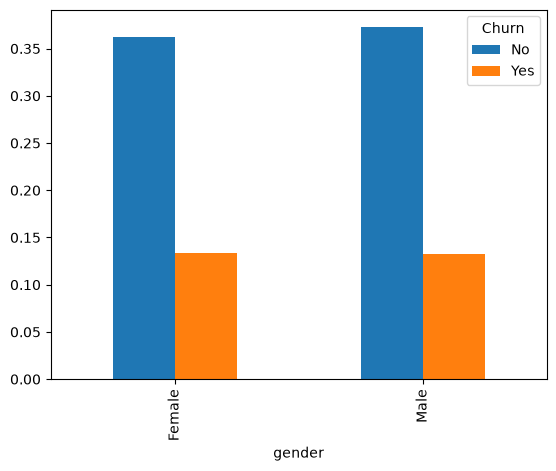

In [389]:
ct = pd.crosstab(df['gender'],df['Churn'],normalize=True)
ct.plot(kind='bar')

proporsi churn rate pada setiap gender cukup imbang

## Partner dan Dependents

=== UJI STATISTIK: Partner vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




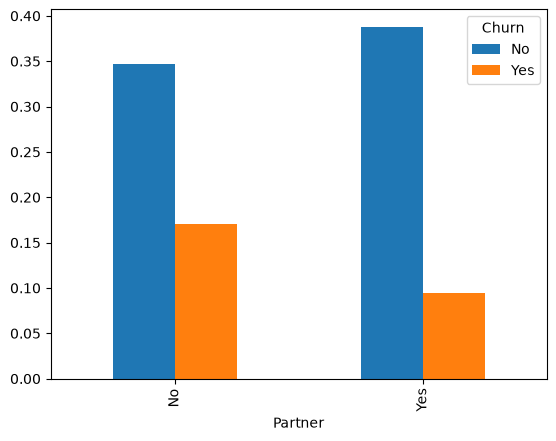

In [390]:
ct =pd.crosstab(df['Partner'],df['Churn'],normalize=True)
ct.plot(kind='bar')
cek_signifikansi_fitur(df,'Partner')


<Axes: xlabel='Partner'>

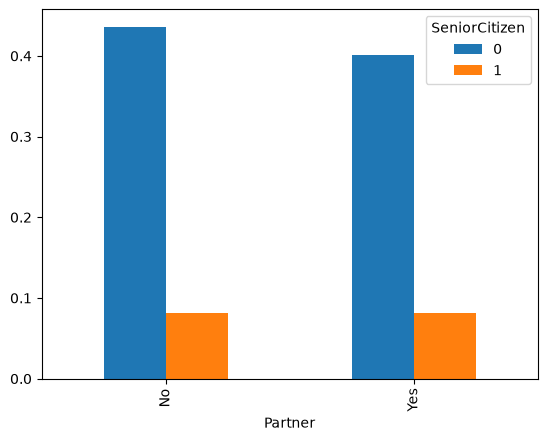

In [391]:
ct = pd.crosstab(df['Partner'],df['SeniorCitizen'],normalize=True)
ct.plot(kind='bar')

<Axes: xlabel='Partner'>

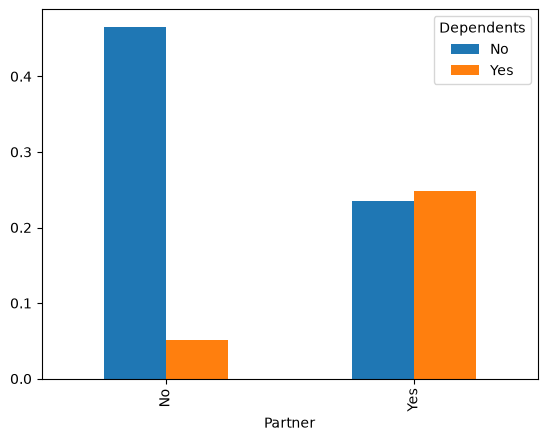

In [392]:
ct = pd.crosstab(df['Partner'],df['Dependents'],normalize=True)
ct.plot(kind='bar')

=== UJI STATISTIK: Dependents vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




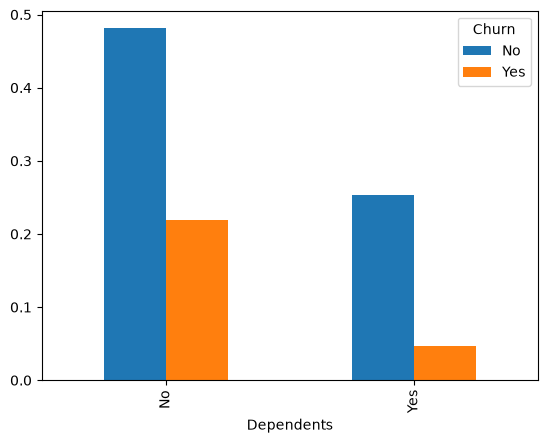

In [393]:
ct =pd.crosstab(df['Dependents'],df['Churn'],normalize=True)
ct.plot(kind='bar')
cek_signifikansi_fitur(df,'Dependents')

Dari analisis berikut kita dapat lihat bahwa partner memiliki signifikansi pada churnrate. kelompok partner cenderung tidak meiliki dependent dan dependent sendiri memiliki signifikansi pada churnrate. orang yang tidak memiliki dependent cenderung memiliki churnrate yang lebih tinggi.
pertanyaan selanjutnya adalah mengapa kelompok yang tidak memiliki partner dan dependents cenderung memiliki chunrrate yang lebih tinggi

In [394]:
display(df.groupby('Partner')['TotalServices'].agg(['mean','median','count']))
display(df.groupby("Partner")['MonthlyCharges'].agg(['mean','median','count']))

,mean,median,count
Partner,,,
No,3.708871,4.0,3641
Yes,4.614345,5.0,3402


,mean,median,count
Partner,,,
No,61.945001,68.65,3641
Yes,67.776264,74.80,3402


melalui analisis diatas, hipotesis yang dilakukan adalah apakah perusahaan ini memberikan layanan paket untuk partner atau tidak sehingga orang yang tidak memiliki partner cenderung tidak mendapatkan banyak keuntungan karena layanan mostly berfokus lebih dari 2. namun hal ini gagal dibuktikan oleh data
dapat dilihat bahwa orang yang tidak memiliki partner cenderung memiliki totalservice yang lebih sedikit dan monthlycharge nya juga cenderung lebih sedikit juga. 
Peneliti tidak menemukan pola atuapun alasan yang jelas terkait kelompok ini sehingga peneliti memutuskan untuk berhenti menelusuri lebih dalam. Oleh karena itu, dibutuhkan penanganan yang lebih lanjut pada kelompok ini

## Paperless Billing

=== UJI STATISTIK: PaperlessBilling vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




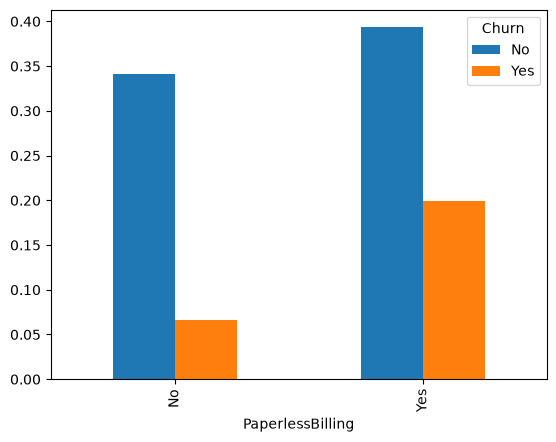

In [395]:
ct = pd.crosstab(df['PaperlessBilling'],df['Churn'],normalize=True)
ct.plot(kind='bar')
cek_signifikansi_fitur(df,'PaperlessBilling')

analisis ini cukup menarik bahwa orang yang melakukan PaperlessBilling cenderung memiliki churnrate yang lebih tinggi, analisis selanjutnya adalah mengapa PaperlessBilling cenderung memiliki churnrate yang lebih tinggi

In [396]:
pd.crosstab(df['PaperlessBilling'],df['PaymentMethod'],normalize=True)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
PaperlessBilling,,,,
No,0.092716,0.090870,0.088457,0.135738
Yes,0.126509,0.125231,0.247338,0.093142


pada analisis ini ditemukan bahwa orang yang paperlessbilling cenderung melakukan pembayaran dengan digital seperti bank transfer, credit card dan electronic check. begitu juga sebaliknya. namun mengapa paperlissbilling cenderung memilik churnrate yang lebih tinggi.

<Axes: xlabel='PaperlessBilling'>

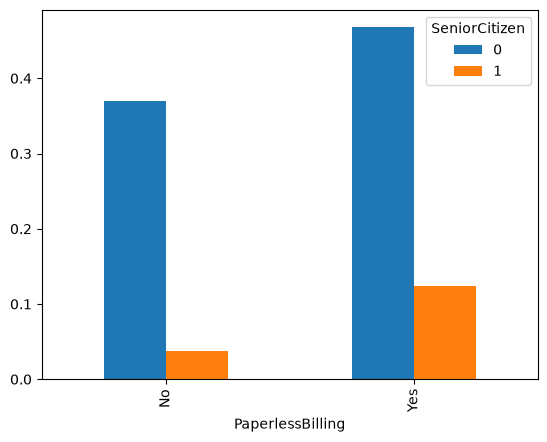

In [397]:
ct = pd.crosstab(df['PaperlessBilling'],df['SeniorCitizen'],normalize=True)
ct.plot(kind='bar')

hal ini ternyata berkaitan dengan senior citizen yang dimana lebih banyak senior citizen yang memiliki paperlessbilling

In [398]:
df.groupby("PaperlessBilling")['TotalServices'].agg(['mean','median','count'])

,mean,median,count
PaperlessBilling,,,
No,3.477368,3.0,2872
Yes,4.606809,5.0,4171


Dalam analisis ini, paperlessbilling memiliki churn rate yang lebih besar daripada orang yang tidak paperlessbilling. namun, berdasarkan data-data disini, tidak ditemukan pola mengapa kelompok tersebut memiliki churn rate yang lebih tingig
asumsi atas kelompok tersebut bisa saja terkait, kesulitan layanan dalam dunia digital, apalagi dari data, kita melihat banyak senior citizen yang melakukan paperlessbilling dan banyak yang melakukan churn. Namun asumsi ini masih belum dibuktikan dengan data karena tidak memiliki variabel tentang kepuasan pelanggan pada fitur paperlessbilling atau kemudahan penggunaan untuk paperlessbilling

## Payment Method

<Axes: xlabel='PaymentMethod'>

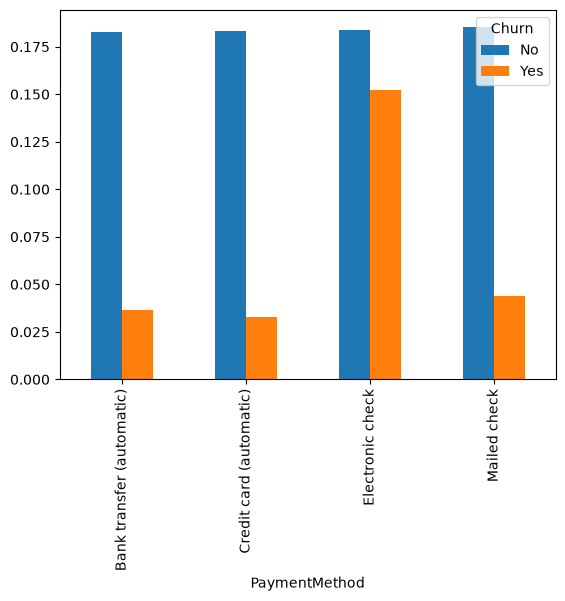

In [399]:
ct = pd.crosstab(df['PaymentMethod'],df['Churn'],normalize=True)
ct.plot(kind='bar')

<Axes: xlabel='PaymentMethod'>

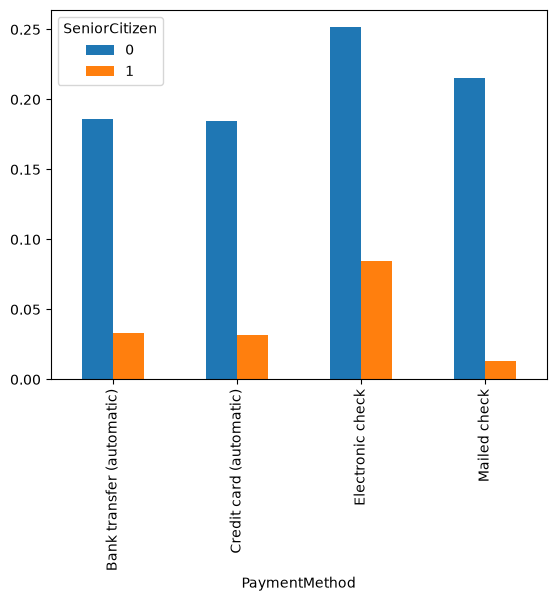

In [400]:
ct = pd.crosstab(df['PaymentMethod'],df['SeniorCitizen'],normalize=True)
ct.plot(kind='bar')

<Axes: xlabel='PaymentMethod'>

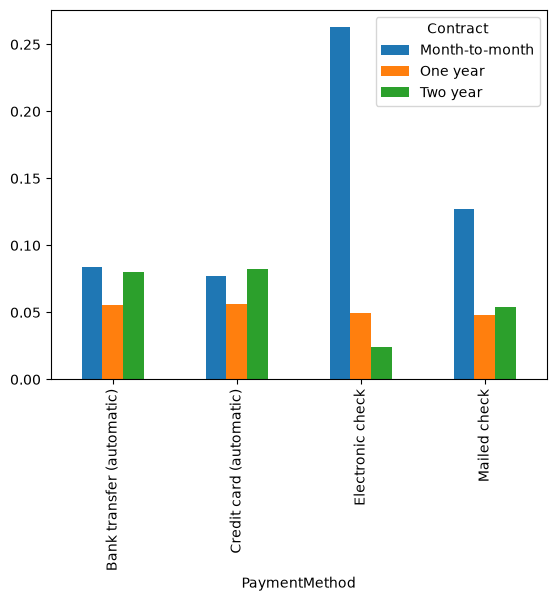

In [401]:
ct = pd.crosstab(df['PaymentMethod'],df['Contract'],normalize=True)
ct.plot(kind='bar')

Berdasarkan analisi berikut, dapat dilihat bahwa kebanyakan orang melakukan pembayaran dengan electronci check lebih berkemungkinan untuk melakukan churn dan kebanyakan senior citizen itu melakukan pembayaran berdasarkan electronic check.
hasil analisa lanjutan juga menunjukkan bahwa orang yang melakukan pembayaran melalui electronic check itu melakukan contract month to month. hal ini berkaitan dengan churnrate contract month to month yang lebih tinggi daripada contract lainnya

Oleh karena itu, langkah bisnis yang dapat diambil adalah memberikan program khusus kepada pelanggan yang melakukan pembyaran secara elctronic check dan contract month to month untuk beralih metode pembayran atau metode kontrak. metode pembayaran yang paling diusulkan adalah bank transfer dan creditccard automatic karena memiliki churn rate yang lebih kecil daripada mail check in. tidak ada variabel lain yang bisa mendukung mengapa pembayaran tersebut lebih murah. hipotesis yang memungkin adalah bahwa pembayaran secara otomatis tidak memberikan dampak psikologi kepada pelanggan untuk memikir ulang terhadap layanan

## Internet Service

In [402]:
display(df.groupby('InternetService')['MonthlyCharges'].agg(['mean','median','count']))
display(pd.crosstab(df['InternetService'], df['Churn'],normalize=True))
cek_signifikansi_fitur(df,'InternetService')

,mean,median,count
InternetService,,,
DSL,58.102169,56.150,2421
Fiber optic,91.500129,91.675,3096
No,21.079194,20.150,1526


Churn,No,Yes
InternetService,,
DSL,0.278574,0.065171
Fiber optic,0.255431,0.184154
No,0.200625,0.016044


=== UJI STATISTIK: InternetService vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




In [403]:
display(df.groupby('InternetService')['tenure'].agg(['mean','median','count']))

,mean,median,count
InternetService,,,
DSL,32.821561,29.0,2421
Fiber optic,32.917959,30.0,3096
No,30.547182,25.0,1526


dari sini kita dapat melihat bahwa internetservice fiber optic menghasilkan profit yang lebih banyak pada perusahaan namun ini wajar karna secara keseluruha fiberoptic memang lebih bagus daripada DSL. namun orang lebih cenderung melakukan churn pada internetservice fiberoptic daripada DSL. setelah dianalisi lebih lanjut, lama pemakaian cenderung sama pada internetservice sehingga tidak terlihat pola jelas pada tenure.

In [404]:
Internet_Services =['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
Fiber_df = df[df['InternetService'] =='Fiber optic']
DSL_df = df[df['InternetService'] == "DSL"]

for i in Internet_Services :
    print(f"columns = {i}")
    print("fiber optic")
    display(pd.crosstab(Fiber_df[i], Fiber_df['Churn'],normalize=True))
    cek_signifikansi_fitur(Fiber_df,i)
    print("DSL")
    display(pd.crosstab(DSL_df[i],DSL_df['Churn'],normalize=True))
    print("========================")
    cek_signifikansi_fitur(DSL_df,i)


columns = OnlineSecurity
fiber optic


Churn,No,Yes
OnlineSecurity,,
No,0.369186,0.359819
Yes,0.211886,0.059109


=== UJI STATISTIK: OnlineSecurity vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------


DSL


Churn,No,Yes
OnlineSecurity,,
No,0.369269,0.143329
Yes,0.441140,0.046262


=== UJI STATISTIK: OnlineSecurity vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------


columns = OnlineBackup
fiber optic


...

=== UJI STATISTIK: StreamingTV vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------


columns = StreamingMovies
fiber optic


Churn,No,Yes
StreamingMovies,,
No,0.235465,0.198966
Yes,0.345607,0.219961


=== UJI STATISTIK: StreamingMovies vs Churn ===
Nilai p-value: 0.00013
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------


DSL


Churn,No,Yes
StreamingMovies,,
No,0.461793,0.133003
Yes,0.348616,0.056588


=== UJI STATISTIK: StreamingMovies vs Churn ===
Nilai p-value: 0.00000
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




Dari semua analisis ini, dapat dilihat bahwa semakin seseorang membeli lebih banyak services, semakin rendah tingkat churnnya. Dapat kita lihat pada kolom online backup, online security, dan techsupp yang memiliki penurunan churn rate yang drastis ketika seseorang memiliki layanan tersebut

sehingga langkah bisnis yang dapat diambil adalah mengusulkan program atau paket yang mendorong pelanggan untuk membeli ketiga service tersebut

In [405]:
for i in Internet_Services :
    print(f"columns = {i}")
    print("fiber optic")
    display(Fiber_df.groupby(i)['MonthlyCharges'].agg(['mean','median','count']))
    print("DSL")
    display(DSL_df.groupby(i)['MonthlyCharges'].agg(['mean','median','count']))
    print("========================")

columns = OnlineSecurity
fiber optic


,mean,median,count
OnlineSecurity,,,
No,88.630217,89.30,2257
Yes,99.220501,100.45,839


DSL


,mean,median,count
OnlineSecurity,,,
No,52.164343,50.6,1241
Yes,64.346949,64.4,1180


columns = OnlineBackup
fiber optic


...

,mean,median,count
StreamingTV,,,
No,50.962500,50.775,1464
Yes,69.024295,70.500,957


columns = StreamingMovies
fiber optic


,mean,median,count
StreamingMovies,,,
No,81.044796,80.00,1345
Yes,99.531211,100.05,1751


DSL


,mean,median,count
StreamingMovies,,,
No,50.853368,50.8,1440
Yes,68.742610,70.3,981


berdasarkan analisi diatas, dapat dilihat bahwa adds on yang cukup menguntungkan adalah pada streaming movies dan streamingTV dengan perbedaan median sebesar 20.

oleh karena itu, jikalau perusahaan mementingkan loyalty, maka akan sangat disarankan untuk memberikan paket bundling royalty yang mencakup onlinebackup, onlinesecurity, dan techsupp. namun, jikalau perusahaan mementingkan revenua, maka akan disarankan untuk memberikan paket bundling streaming tvs dan streaming movies kepada pelanggan.

## Phone Service

In [406]:
display(pd.crosstab(df['PhoneService'],df['Churn'],normalize=True))
cek_signifikansi_fitur(df,"PhoneService")

Churn,No,Yes
PhoneService,,
No,0.072696,0.024137
Yes,0.661934,0.241232


=== UJI STATISTIK: PhoneService vs Churn ===
Nilai p-value: 0.33878
👉 Status: **TIDAK SIGNIFIKAN** (Perbedaan proporsinya bisa jadi cuma karena kebetulan data).
--------------------------------------------------




berdasarkan analisis, phoneservice terbukti tidak memiliki signifikansi pada churn. mengapa? hal ini bisa dikarenakan proporsi phoneservice yang timpang pada yes. pada analisis categorical analysis. kita melihat bahwa banyak orang yang mempunyai phone service. Oleh karena itu, untuk analisis lebih lanjut akan dilihat pada multiple lines

<Axes: xlabel='MultipleLines'>

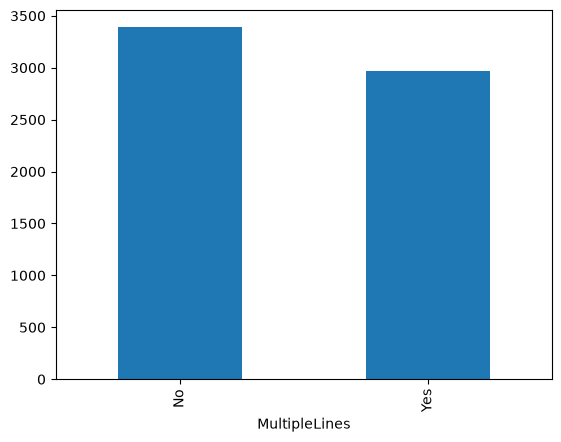

In [407]:
Phone_df = df[df['PhoneService'] == "Yes"]
ct = Phone_df['MultipleLines'].value_counts()
ct.plot(kind='bar')

proporsi multiple lines cukup seimbang

In [408]:
display(pd.crosstab(Phone_df['MultipleLines'],Phone_df['Churn'],normalize=True))
cek_signifikansi_fitur(Phone_df,"MultipleLines")

Churn,No,Yes
MultipleLines,,
No,0.399465,0.133470
Yes,0.333438,0.133627


=== UJI STATISTIK: MultipleLines vs Churn ===
Nilai p-value: 0.00148
👉 Status: **SIGNIFIKAN** (Perbedaan proporsinya nyata, kecil kemungkinan karena kebetulan).
--------------------------------------------------




In [409]:
display(Phone_df.groupby("MultipleLines")['MonthlyCharges'].agg(['mean','median','count']))
display(Phone_df.groupby("Churn")['MonthlyCharges'].agg(['mean','median','count']))

,mean,median,count
MultipleLines,,,
No,54.195059,55.975,3390
Yes,82.036974,88.050,2971


,mean,median,count
Churn,,,
No,63.213857,69.85,4662
Yes,78.134255,80.95,1699


berdasarkan temuan ini, hasil praktis variabel menunjukkan tidak ada pola signifikan pada multiple lines namun, hasil p-value menunjukkan adnaya signifikan. selain itu, dengan adanya multipleline service sudah pasti memiliki monthlycharges yang lebih besar. dan monthlycharges yang lebih besar ini memiliki churn rate yang lebih besar juga.

# Machine Learning

In [410]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

## Preprocessing

In [411]:
service_cols =['MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling','PhoneService','Partner','Dependents','Churn']
for i in service_cols :
    print(f"columns = {i}")
    df[i] = df[i].replace({"No":"No","Yes":"Yes",'No internet service':'No' ,"No phone service":'No'})
    df[i] = df[i].replace({'Yes':1,"No":0})
    df[i] = pd.to_numeric(df[i],errors="coerce").astype("int64")
df['gender'] = df['gender'].replace({"Male":0,"Female":1})
df['gender'] = pd.to_numeric(df['gender'], errors="coerce").astype("int64")
df.isnull().sum()

columns = MultipleLines
columns = OnlineSecurity
columns = OnlineBackup
columns = DeviceProtection
columns = TechSupport
columns = StreamingTV
columns = StreamingMovies
columns = PaperlessBilling
columns = PhoneService
columns = Partner
columns = Dependents
columns = Churn


gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TotalServices       0
dtype: int64

In [412]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   int64  
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   int64  
 9   OnlineBackup      7043 non-null   int64  
 10  DeviceProtection  7043 non-null   int64  
 11  TechSupport       7043 non-null   int64  
 12  StreamingTV       7043 non-null   int64  
 13  StreamingMovies   7043 non-null   int64  
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [413]:
num_cols =['MonthlyCharges','TotalCharges']
for i in num_cols:
    df[i +"_log"] = np.log1p(df[i])

In [414]:
categorical_cols = ['InternetService', 'Contract', 'PaymentMethod']

# 2. Terapkan pd.get_dummies untuk mengubahnya menjadi kolom biner (0 dan 1)
# drop_first=True sangat disarankan untuk menghindari 'dummy variable trap' (kolom ganda yang redundan)
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

## Split data

In [415]:
from sklearn.model_selection import train_test_split


X = df_encoded.drop(columns=['Churn']) 
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [416]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Kolom numerik yang sudah disiapkan
num_cols = ['tenure', 'MonthlyCharges_log', 'TotalCharges_log','MonthlyCharges','TotalCharges','TotalServices'] 

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## Logistic Regression

In [417]:
X_train_no_log = X_train.drop(columns=['MonthlyCharges_log','TotalCharges_log'])
X_test_no_log = X_test.drop(columns=['MonthlyCharges_log','TotalCharges_log'])

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report


logis_model_base = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

logis_model_base.fit(X_train_no_log, y_train)

# 3. Predict (Membuat prediksi pada data testing)
y_pred = logis_model_base.predict(X_test_no_log)

# 4. Menghitung Accuracy dan F1-Score
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted') # atau average='binary'/'macro'

print(f"Accuracy Score: {acc:.4f}")
print(f"F1-Score: {f1:.4f}")

# (Opsional) Untuk melihat detail lengkap per kelas
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.7395
F1-Score: 0.7533

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [418]:
X_train_with_log = X_train.drop(columns=['MonthlyCharges','TotalCharges'])
X_test_with_log = X_test.drop(columns=['MonthlyCharges','TotalCharges'])


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report


logis_model_base_log = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

logis_model_base_log.fit(X_train_with_log, y_train)

# 3. Predict (Membuat prediksi pada data testing)
y_pred = logis_model_base_log.predict(X_test_with_log)

# 4. Menghitung Accuracy dan F1-Score
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted') # atau average='binary'/'macro'

print(f"Accuracy Score: {acc:.4f}")
print(f"F1-Score: {f1:.4f}")

# (Opsional) Untuk melihat detail lengkap per kelas
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.7410
F1-Score: 0.7548

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [419]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Inisialisasi model dasar
base_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# 2. Tentukan daftar parameter yang ingin diuji coba
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100], # Kekuatan regularisasi
    'penalty': ['l1', 'l2'],                # Jenis regularisasi
    'solver': ['liblinear']                 # solver 'liblinear' mendukung l1 dan l2
}

# 3. Inisialisasi GridSearchCV
# Kita pakai scoring='f1' atau 'roc_auc' (atau 'f1_weighted' sesuai preferensimu)
grid_search = GridSearchCV(
    estimator=base_lr,
    param_grid=param_grid,
    cv=5,                 # 5-Fold Cross Validation
    scoring='f1_weighted', # Metrik acuan pencarian terbaik
    n_jobs=-1             # Memakai semua core CPU biar cepat
)

# 4. Jalankan pencarian pada data train (tanpa log)
grid_search.fit(X_train_with_log, y_train)

# 5. Lihat hasil terbaiknya
print("Parameter Terbaik:", grid_search.best_params_)
print(f"Skor Terbaik (CV): {grid_search.best_score_:.4f}")

# 6. Ambil model terbaik hasil tuning
best_logreg_model = grid_search.best_estimator_

Parameter Terbaik: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Skor Terbaik (CV): 0.7702


c:\Users\redmi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [420]:
y_pred_best_logreg = best_logreg_model.predict(X_test_with_log)

acc_best_logreg = accuracy_score(y_test, y_pred_best_logreg)
f1_best_logreg = f1_score(y_test, y_pred_best_logreg, average='weighted')

print(f"Accuracy Score (Tuned LogReg): {acc_best_logreg:.4f}")
print(f"F1-Score (Tuned LogReg): {f1_best_logreg:.4f}")

# 3. Menampilkan Classification Report lengkap
print("\nClassification Report (Tuned LogReg):")
print(classification_report(y_test, y_pred_best_logreg))

Accuracy Score (Tuned LogReg): 0.7431
F1-Score (Tuned LogReg): 0.7567

Classification Report (Tuned LogReg):
              precision    recall  f1-score   support

           0       0.91      0.72      0.81      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



## Random Forest

In [421]:
from sklearn.ensemble import RandomForestClassifier

# 1. Inisialisasi model Random Forest (gunakan class_weight='balanced' juga)
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')

# 2. Train menggunakan data asli (misalnya X_train awal sebelum log)
# Pastikan X_train awal sudah di-encoding ya
rf_model.fit(X_train_no_log, y_train)

# 3. Predict
y_pred_rf = rf_model.predict(X_test_no_log)

# 4. Evaluasi
print(f"Accuracy Score (RF): {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score (RF): {f1_score(y_test, y_pred_rf, average='weighted'):.4f}")
print("\nClassification Report (RF):")
print(classification_report(y_test, y_pred_rf))

Accuracy Score (RF): 0.7722
F1-Score (RF): 0.7770

Classification Report (RF):
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.56      0.65      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



In [422]:
base_rf = RandomForestClassifier(class_weight='balanced', random_state=42)

param_grid_rf = {
    'n_estimators': [50, 100, 200],       # Jumlah pohon keputusan
    'max_depth': [10, 20, None],          # Maksimal kedalaman pohon
    'min_samples_split': [2, 5, 10],      # Minimum sampel untuk memecah node
    'min_samples_leaf': [1, 2, 4]         # Minimum sampel di leaf node
}


grid_search_rf = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid_rf,
    cv=5,                
    scoring='f1_weighted', 
    n_jobs=-1             
)


grid_search_rf.fit(X_train_no_log, y_train)


print("Parameter Terbaik (RF):", grid_search_rf.best_params_)
print(f"Skor Terbaik (CV): {grid_search_rf.best_score_:.4f}")


best_rf_model = grid_search_rf.best_estimator_


y_pred_best_rf = best_rf_model.predict(X_test_no_log)

print(f"\nAccuracy Score (Tuned RF): {accuracy_score(y_test, y_pred_best_rf):.4f}")
print(f"F1-Score (Tuned RF): {f1_score(y_test, y_pred_best_rf, average='weighted'):.4f}")

print("\nClassification Report (Tuned RF):")
print(classification_report(y_test, y_pred_best_rf))

Parameter Terbaik (RF): {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Skor Terbaik (CV): 0.7843

Accuracy Score (Tuned RF): 0.7729
F1-Score (Tuned RF): 0.7781

Classification Report (Tuned RF):
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.56      0.66      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409



## XGBoost Model

In [423]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier(random_state=42)

xgb_model.fit(X_train_no_log, y_train)


y_pred_xgb = xgb_model.predict(X_test_no_log)

print(f"Accuracy Score (XGBoost): {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"F1-Score (XGBoost): {f1_score(y_test, y_pred_xgb, average='weighted'):.4f}")

print("\nClassification Report (XGBoost):")
print(classification_report(y_test, y_pred_xgb))

Accuracy Score (XGBoost): 0.7835
F1-Score (XGBoost): 0.7785

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.61      0.53      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.78      0.78      0.78      1409



In [424]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

base_xgb = xgb.XGBClassifier(
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric='logloss'
)

param_grid_xgb = {
    'n_estimators': [50, 100, 200],     
    'max_depth': [3, 5, 7],              
    'learning_rate': [0.01, 0.1, 0.2],    
    'subsample': [0.8, 1.0]              
}


grid_search_xgb = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid_xgb,
    cv=5,                 
    scoring='f1_weighted', 
    n_jobs=-1             
)


grid_search_xgb.fit(X_train_no_log, y_train)


print("Parameter Terbaik (XGBoost):", grid_search_xgb.best_params_)
print(f"Skor Terbaik (CV): {grid_search_xgb.best_score_:.4f}")


best_xgb_model = grid_search_xgb.best_estimator_


y_pred_best_xgb = best_xgb_model.predict(X_test_no_log)

print(f"\nAccuracy Score (Tuned XGBoost): {accuracy_score(y_test, y_pred_best_xgb):.4f}")
print(f"F1-Score (Tuned XGBoost): {f1_score(y_test, y_pred_best_xgb, average='weighted'):.4f}")

print("\nClassification Report (Tuned XGBoost):")
print(classification_report(y_test, y_pred_best_xgb))

Parameter Terbaik (XGBoost): {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Skor Terbaik (CV): 0.7730

Accuracy Score (Tuned XGBoost): 0.7622
F1-Score (Tuned XGBoost): 0.7721

Classification Report (Tuned XGBoost):
              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1035
           1       0.54      0.73      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



# Final Model

In [425]:
best_xgb_model = xgb_model
y_pred_best_xgb = best_xgb_model.predict(X_test_no_log)

print(f"\nAccuracy Score (Tuned XGBoost): {accuracy_score(y_test, y_pred_best_xgb):.4f}")
print(f"F1-Score (Tuned XGBoost): {f1_score(y_test, y_pred_best_xgb, average='weighted'):.4f}")

print("\nClassification Report (Tuned XGBoost):")
print(classification_report(y_test, y_pred_best_xgb))


Accuracy Score (Tuned XGBoost): 0.7835
F1-Score (Tuned XGBoost): 0.7785

Classification Report (Tuned XGBoost):
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.61      0.53      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.78      0.78      0.78      1409



In [426]:
final_xgb_model = xgb_model
import joblib

X_full = df_encoded.drop(columns=['Churn','MonthlyCharges_log','TotalCharges_log']) # Sesuaikan nama kolom targetmu
y_full = df_encoded['Churn']
num_cols = ['tenure', 'MonthlyCharges','TotalCharges','TotalServices'] 

X_full[num_cols] = scaler.fit_transform(X_full[num_cols])

# 3. Latih model menggunakan SELURUH data
final_xgb_model.fit(X_full, y_full)

print("Final model berhasil dilatih dengan seluruh data!")


joblib.dump(final_xgb_model, 'telco_churn_final_xgboost_model.pkl')
print("Model final berhasil disimpan sebagai 'telco_churn_final_xgboost_model.pkl'")


Final model berhasil dilatih dengan seluruh data!
Model final berhasil disimpan sebagai 'telco_churn_final_xgboost_model.pkl'


berdasarkan hasil eksperimen, ditemukan model yang paling optimal adalah xgb_model dengan accuracy 0.7834 dan f1score = 0.7785. model tidak dilatih dengan scale_pos_weight meskipun terdapat imbalance class di churn dikarenakan model baseline memiliki yang lebih optimal. Xgboost sendiri merupakan model yang cukup tahan pada class imbalance dan mampu memecah fitur dengan sendirinya. selain itu, model dilatih tanpa variabel log. karena model tree seperti XGBoost sudah bisa mengenali polanya dengan sendiri, sedangkan untuk logistic regression diuji cobakan menggunakan log dan tanpa log. secara keseluruhan Logistic regression lebih baik dengan menggunakan log, random forest lebih baik daripada logistic regression, dan baseline xgboost lebih baik dari keseluruhan model. oleh karena itu, keputusan akhir adalah menggunakan baseline xgb_model sebagia final_model